In [1]:
# ============================================
# Appliance Energy Prediction
# Analyst Notebook
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load dataset

df = pd.read_csv(r"C:\Users\Vision\Downloads\appliances+energy+prediction\energydata_complete.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (19735, 29)


In [3]:
# First look at the dataset

display(df.head())

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [4]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [5]:
# Dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 19735
Number of columns: 29


In [6]:
# ============================================
# 2. Dataset Understanding
# ============================================

print("Dataset Shape:", df.shape)
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())
print("Number of Unique Dates:", df["date"].nunique())

Dataset Shape: (19735, 29)
Start Date: 2016-01-11 17:00:00
End Date: 2016-05-27 18:00:00
Number of Unique Dates: 19735


In [7]:
# Missing values

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

Total missing values: 0


Series([], dtype: int64)

In [8]:
# Duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [9]:
# Check time intervals

date_temp = pd.to_datetime(df["date"])

time_diff = date_temp.diff().dropna()

print("Most common time interval:")
print(time_diff.value_counts().head())

print("\nMinimum interval:", time_diff.min())
print("Maximum interval:", time_diff.max())

Most common time interval:
date
0 days 00:10:00    19734
Name: count, dtype: int64

Minimum interval: 0 days 00:10:00
Maximum interval: 0 days 00:10:00


In [10]:
# Unique values per column

unique_counts = df.nunique().sort_values()

display(unique_counts)

lights             8
Appliances        92
Windspeed        189
Visibility       413
RH_out           566
T1               722
T9               924
T4              1390
Tdewpoint       1409
T3              1426
T2              1650
T_out           1730
T7              1955
Press_mm_hg     2189
T8              2228
T5              2263
RH_1            2547
RH_3            2618
RH_4            2987
RH_2            3376
RH_9            3388
T6              4446
RH_7            5891
RH_8            6649
RH_5            7571
RH_6            9709
date           19735
rv1            19735
rv2            19735
dtype: int64

In [11]:
# ============================================
# 3. Data Dictionary
# ============================================

data_dictionary = {
    "date": "Timestamp of the measurement",
    "Appliances": "Appliance energy consumption (Wh)",
    "lights": "Lighting energy consumption (Wh)",
    "T1": "Temperature in kitchen area (°C)",
    "RH_1": "Humidity in kitchen area (%)",
    "T2": "Temperature in living room area (°C)",
    "RH_2": "Humidity in living room area (%)",
    "T3": "Temperature in laundry room area (°C)",
    "RH_3": "Humidity in laundry room area (%)",
    "T4": "Temperature in office room (°C)",
    "RH_4": "Humidity in office room (%)",
    "T5": "Temperature in bathroom (°C)",
    "RH_5": "Humidity in bathroom (%)",
    "T6": "Temperature outside the building (north side) (°C)",
    "RH_6": "Humidity outside the building (north side) (%)",
    "T7": "Temperature in ironing room (°C)",
    "RH_7": "Humidity in ironing room (%)",
    "T8": "Temperature in teenager room 2 (°C)",
    "RH_8": "Humidity in teenager room 2 (%)",
    "T9": "Temperature in parents room (°C)",
    "RH_9": "Humidity in parents room (%)",
    "T_out": "Outdoor temperature from weather station (°C)",
    "Press_mm_hg": "Atmospheric pressure (mm Hg)",
    "RH_out": "Outdoor relative humidity (%)",
    "Windspeed": "Wind speed (m/s)",
    "Visibility": "Visibility (km)",
    "Tdewpoint": "Dewpoint temperature (°C)",
    "rv1": "Random variable",
    "rv2": "Random variable"
}

data_dictionary_df = pd.DataFrame(
    list(data_dictionary.items()),
    columns=["Feature", "Description"]
)

display(data_dictionary_df)

,Feature,Description
0,date,Timestamp of the measurement
1,Appliances,Appliance energy consumption (Wh)
2,lights,Lighting energy consumption (Wh)
3,T1,Temperature in kitchen area (°C)
4,RH_1,Humidity in kitchen area (%)
5,T2,Temperature in living room area (°C)
6,RH_2,Humidity in living room area (%)
7,T3,Temperature in laundry room area (°C)
8,RH_3,Humidity in laundry room area (%)
9,T4,Temperature in office room (°C)


In [12]:
# Check Data Dictionary coverage

missing_from_dictionary = set(df.columns) - set(data_dictionary_df["Feature"])
extra_in_dictionary = set(data_dictionary_df["Feature"]) - set(df.columns)

print("Columns missing from dictionary:", missing_from_dictionary)
print("Extra columns in dictionary:", extra_in_dictionary)

Columns missing from dictionary: set()
Extra columns in dictionary: set()


In [13]:
# ============================================
# 4. Statistical Analysis
# ============================================

numeric_columns = df.select_dtypes(include=np.number).columns

descriptive_stats = df[numeric_columns].describe().T

display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [14]:
# Target statistical summary

target_stats = df["Appliances"].describe()

display(target_stats)

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

In [15]:
# Target quantiles

target_quantiles = df["Appliances"].quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(target_quantiles)

0.01     20.0
0.05     30.0
0.10     40.0
0.25     50.0
0.50     60.0
0.75    100.0
0.90    196.0
0.95    330.0
0.99    576.6
Name: Appliances, dtype: float64

In [16]:
# Mean vs Median

mean_median = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median()
})

mean_median["Mean_Median_Difference"] = (
    mean_median["Mean"] - mean_median["Median"]
)

display(mean_median)

,Mean,Median,Mean_Median_Difference
Appliances,97.694958,60.000000,37.694958
lights,3.801875,0.000000,3.801875
T1,21.686571,21.600000,0.086571
RH_1,40.259739,39.656667,0.603073
T2,20.341219,20.000000,0.341219
RH_2,40.420420,40.500000,-0.079580
T3,22.267611,22.100000,0.167611
RH_3,39.242500,38.530000,0.712500
T4,20.855335,20.666667,0.188668
RH_4,39.026904,38.400000,0.626904


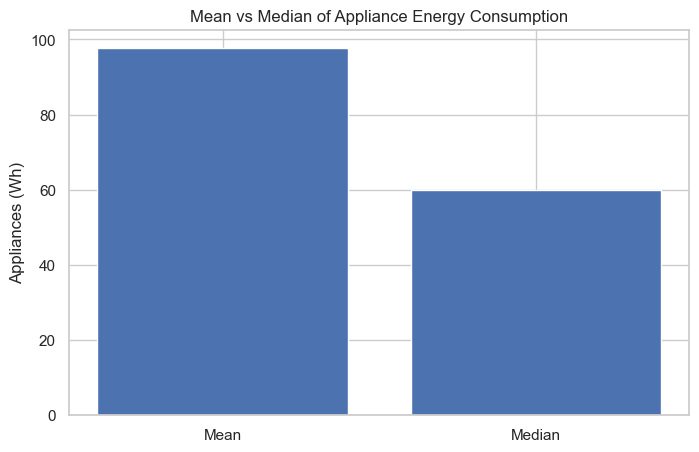

In [17]:
# Mean vs Median of target

plt.figure(figsize=(8, 5))

plt.bar(
    ["Mean", "Median"],
    [df["Appliances"].mean(), df["Appliances"].median()]
)

plt.title("Mean vs Median of Appliance Energy Consumption")
plt.ylabel("Appliances (Wh)")
plt.show()

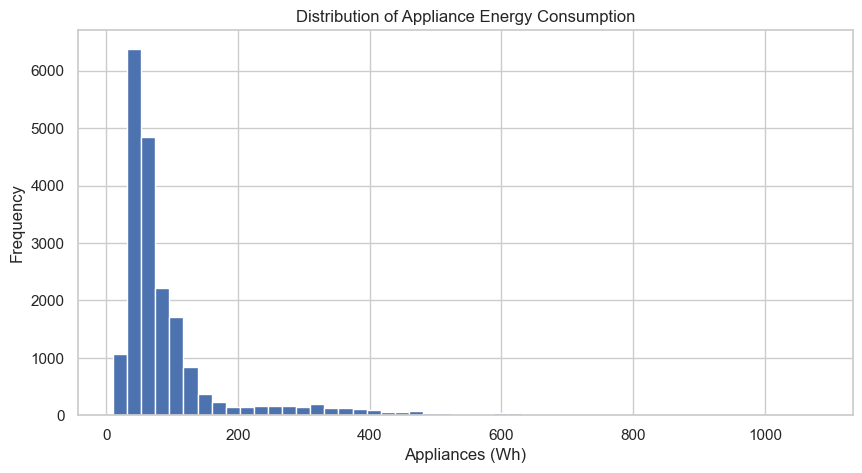

In [18]:
# ============================================
# 5. Distribution Analysis
# ============================================

plt.figure(figsize=(10, 5))

plt.hist(df["Appliances"], bins=50)

plt.title("Distribution of Appliance Energy Consumption")
plt.xlabel("Appliances (Wh)")
plt.ylabel("Frequency")

plt.show()

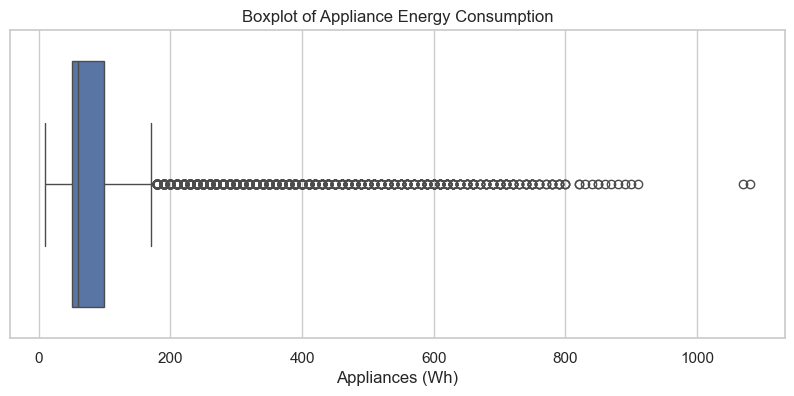

In [19]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Appliances"])

plt.title("Boxplot of Appliance Energy Consumption")
plt.xlabel("Appliances (Wh)")

plt.show()

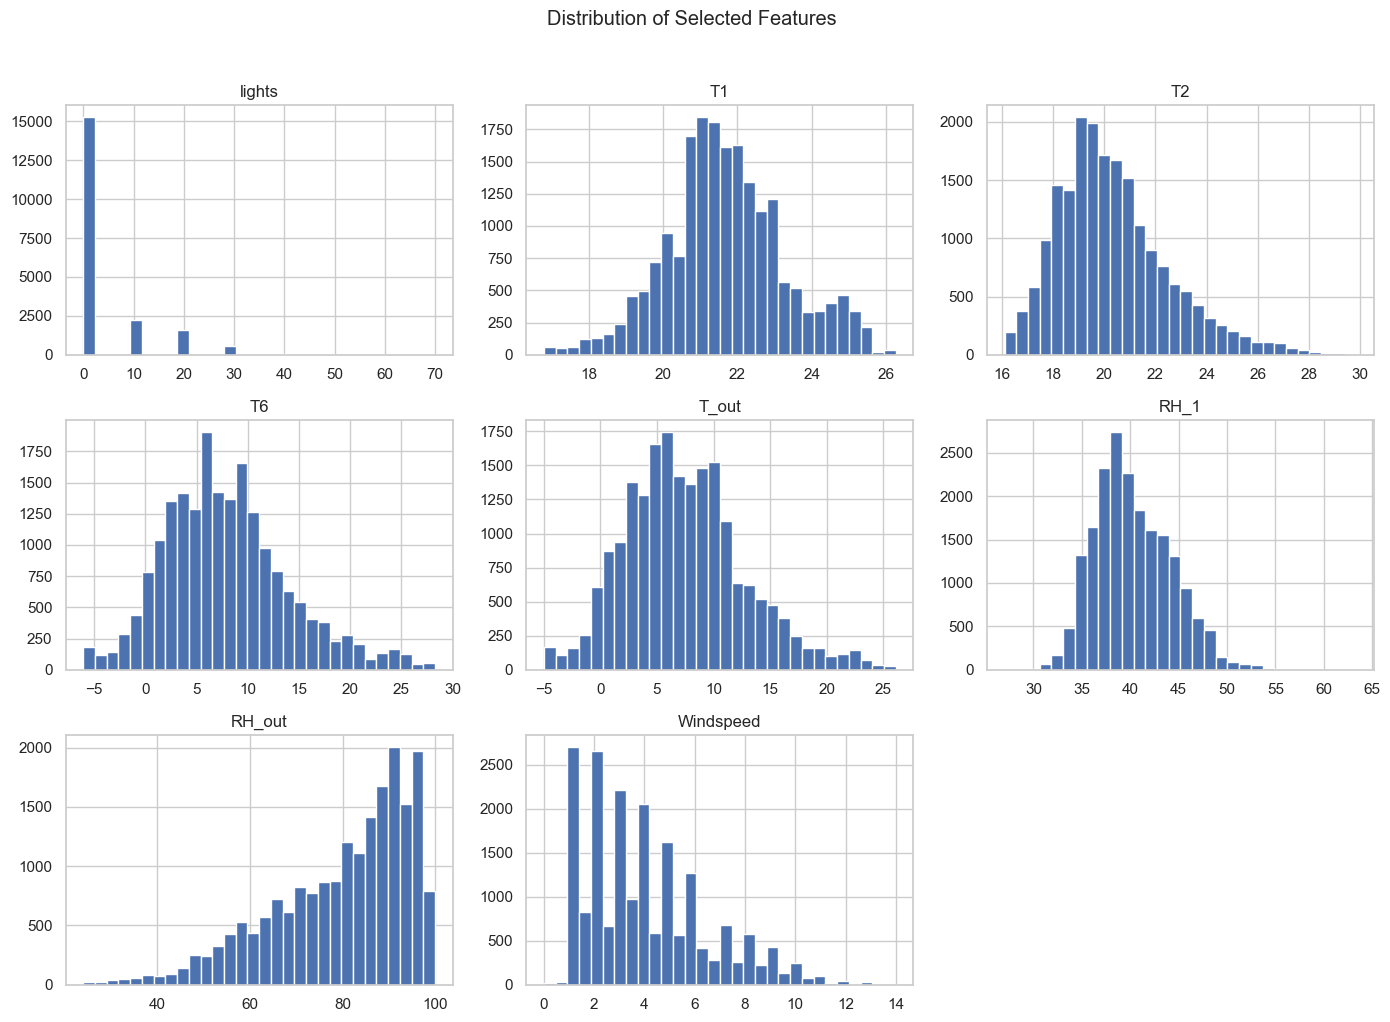

In [20]:
selected_features = [
    "lights",
    "T1",
    "T2",
    "T6",
    "T_out",
    "RH_1",
    "RH_out",
    "Windspeed"
]

df[selected_features].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Selected Features", y=1.02)
plt.tight_layout()
plt.show()

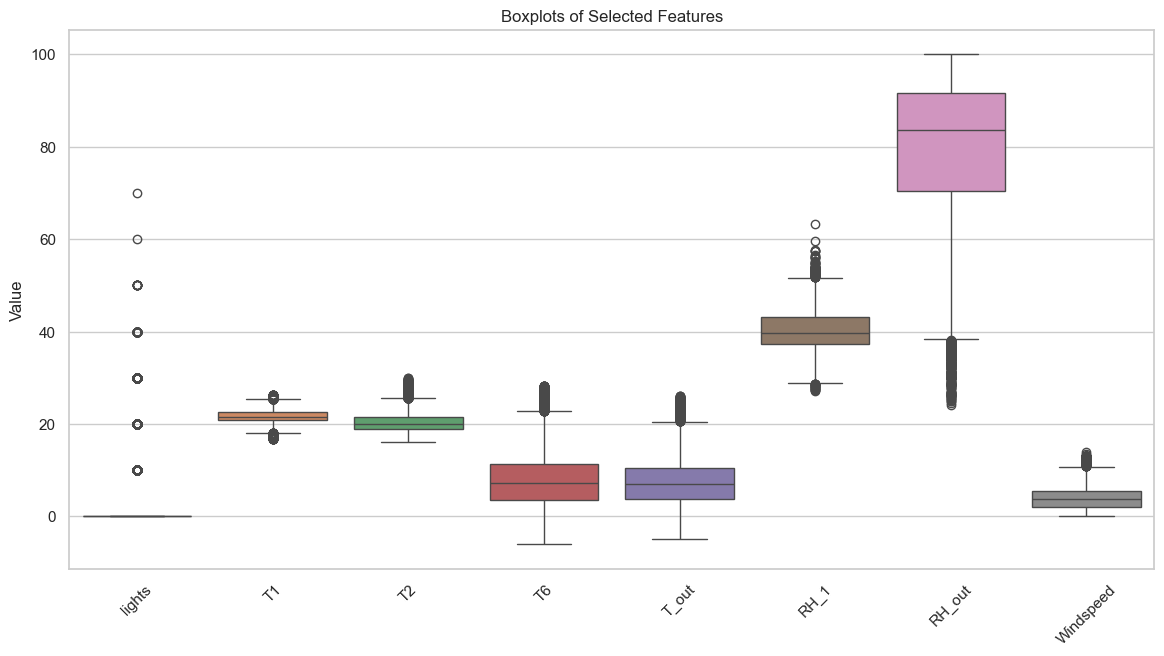

In [21]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df[selected_features])

plt.title("Boxplots of Selected Features")
plt.xticks(rotation=45)
plt.ylabel("Value")

plt.show()

In [22]:
# ============================================
# 6. Time-Based Analysis
# ============================================

df["date"] = pd.to_datetime(df["date"])

df["hour"] = df["date"].dt.hour
df["day_of_week"] = df["date"].dt.dayofweek
df["day_name"] = df["date"].dt.day_name()

print("Time features created successfully.")
display(df[["date", "hour", "day_of_week", "day_name"]].head())

Time features created successfully.


,date,hour,day_of_week,day_name
0,2016-01-11 17:00:00,17,0,Monday
1,2016-01-11 17:10:00,17,0,Monday
2,2016-01-11 17:20:00,17,0,Monday
3,2016-01-11 17:30:00,17,0,Monday
4,2016-01-11 17:40:00,17,0,Monday


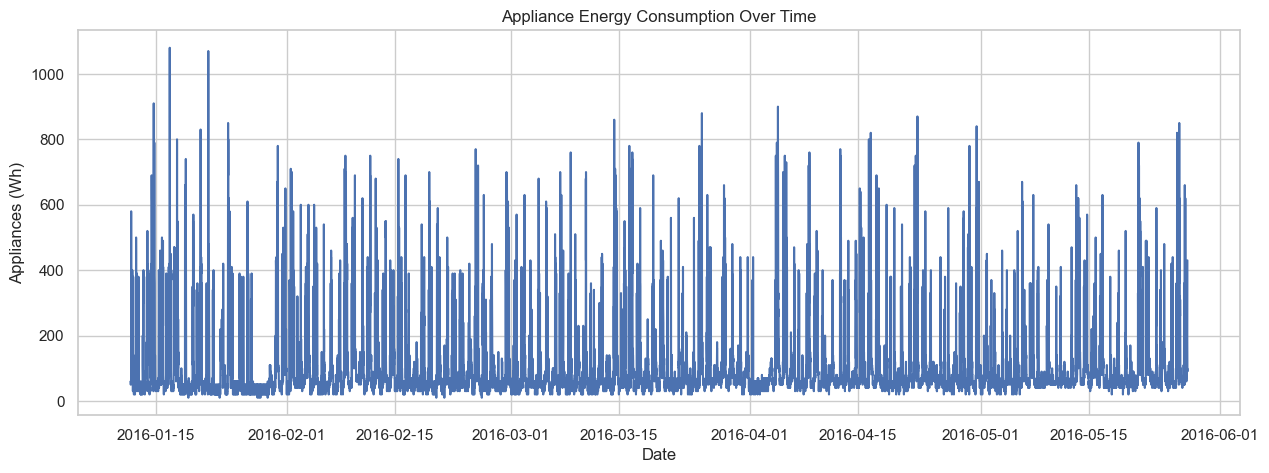

In [23]:
plt.figure(figsize=(15, 5))

plt.plot(df["date"], df["Appliances"])

plt.title("Appliance Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Appliances (Wh)")

plt.show()

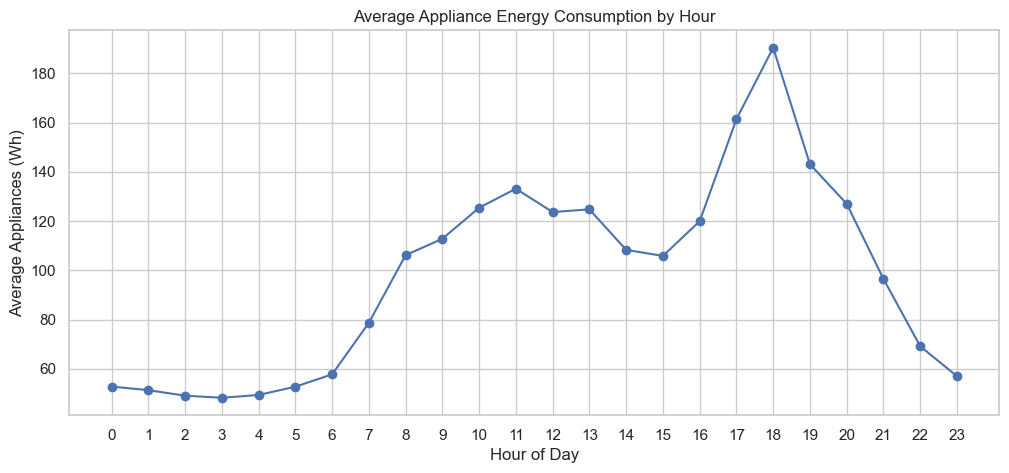

hour
0      52.785888
1      51.326034
2      49.075426
3      48.236010
4      49.355231
5      52.737226
6      57.712895
7      78.649635
8     106.143552
9     112.785888
10    125.377129
11    133.126521
12    123.637470
13    124.744526
14    108.284672
15    105.827251
16    119.902676
17    161.352657
18    190.364520
19    143.065693
20    126.982968
21     96.496350
22     69.148418
23     56.982968
Name: Appliances, dtype: float64

In [24]:
hourly_consumption = df.groupby("hour")["Appliances"].mean()

plt.figure(figsize=(12, 5))

plt.plot(hourly_consumption.index, hourly_consumption.values, marker="o")

plt.title("Average Appliance Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Appliances (Wh)")
plt.xticks(range(24))

plt.show()

display(hourly_consumption)

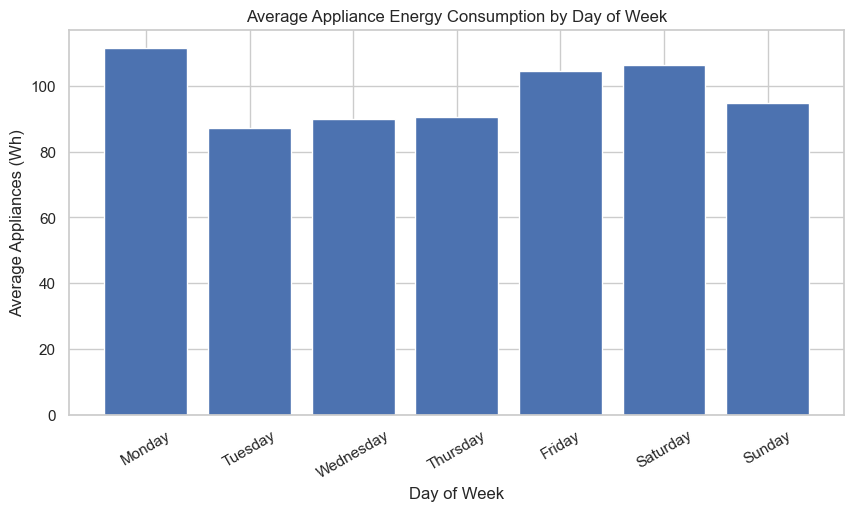

day_of_week
0    111.450684
1     87.125000
2     89.930556
3     90.434028
4    104.622144
5    106.246345
6     94.915936
Name: Appliances, dtype: float64

In [25]:
weekly_consumption = df.groupby("day_of_week")["Appliances"].mean()

day_labels = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10, 5))

plt.bar(day_labels, weekly_consumption.values)

plt.title("Average Appliance Energy Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Appliances (Wh)")
plt.xticks(rotation=30)

plt.show()

display(weekly_consumption)

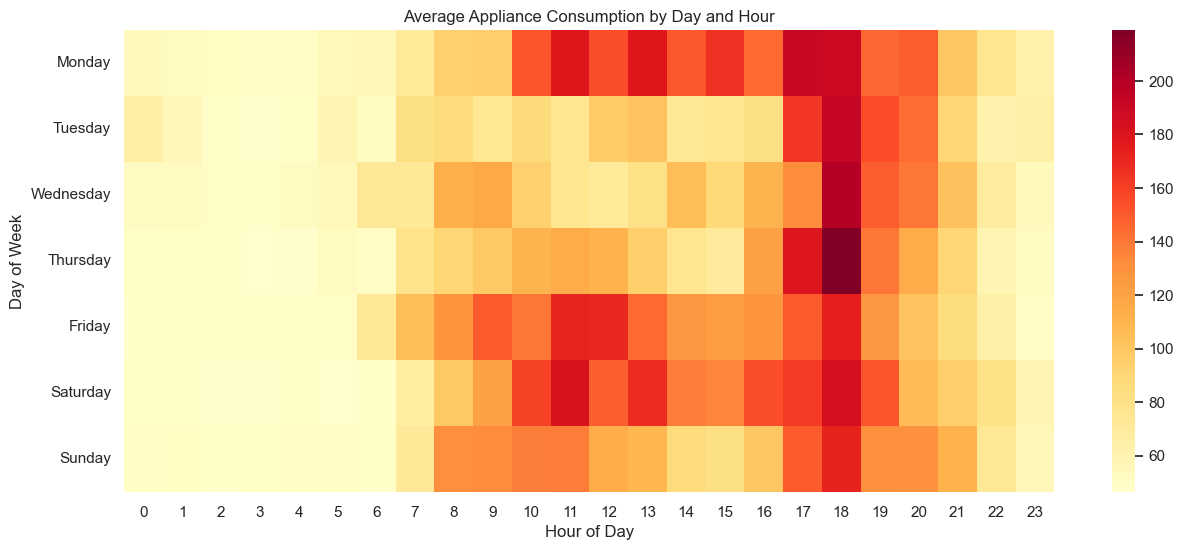

In [26]:
hour_day_consumption = df.pivot_table(
    values="Appliances",
    index="day_of_week",
    columns="hour",
    aggfunc="mean"
)

hour_day_consumption.index = day_labels

plt.figure(figsize=(15, 6))

sns.heatmap(
    hour_day_consumption,
    annot=False,
    cmap="YlOrRd"
)

plt.title("Average Appliance Consumption by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

plt.show()

In [27]:
# ============================================
# 7. Feature-Target Relationship
# ============================================

correlation_with_target = (
    df.select_dtypes(include=np.number)
      .corr()["Appliances"]
      .sort_values()
)

display(correlation_with_target)

RH_out        -0.152282
RH_8          -0.094039
RH_6          -0.083178
RH_2          -0.060465
RH_7          -0.055642
RH_9          -0.051462
Press_mm_hg   -0.034885
rv2           -0.011145
rv1           -0.011145
Visibility     0.000230
day_of_week    0.003060
RH_5           0.006955
T9             0.010010
Tdewpoint      0.015353
RH_4           0.016965
T5             0.019760
T7             0.025801
RH_3           0.036292
T8             0.039572
T4             0.040281
T1             0.055447
T3             0.085060
RH_1           0.086031
Windspeed      0.087122
T_out          0.099155
T6             0.117638
T2             0.120073
lights         0.197278
hour           0.216792
Appliances     1.000000
Name: Appliances, dtype: float64

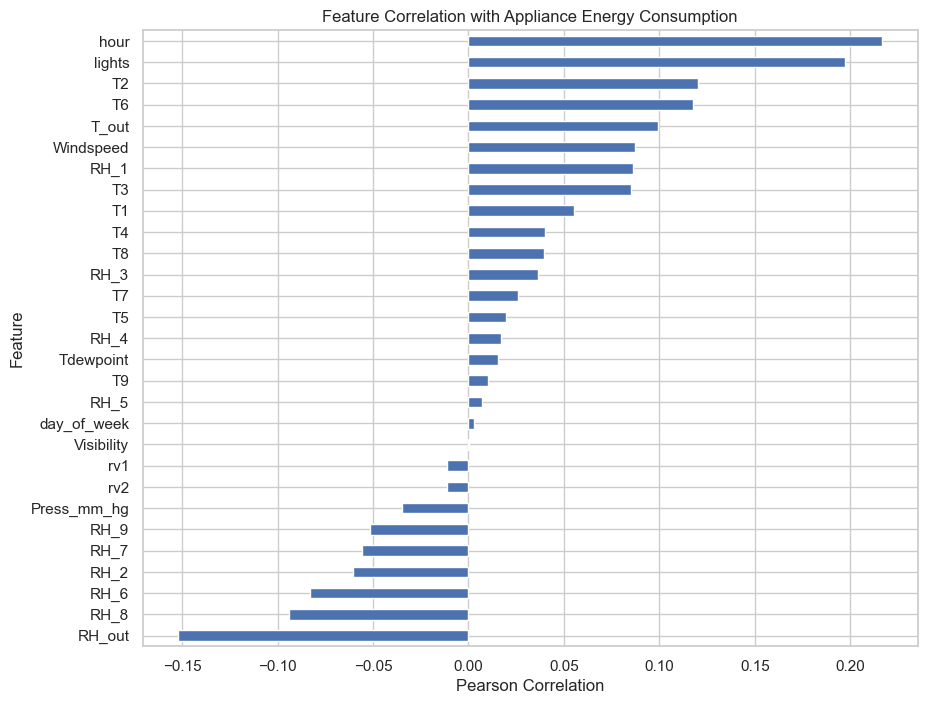

In [28]:
feature_target_corr = correlation_with_target.drop("Appliances")

plt.figure(figsize=(10, 8))

feature_target_corr.sort_values().plot(kind="barh")

plt.title("Feature Correlation with Appliance Energy Consumption")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.show()

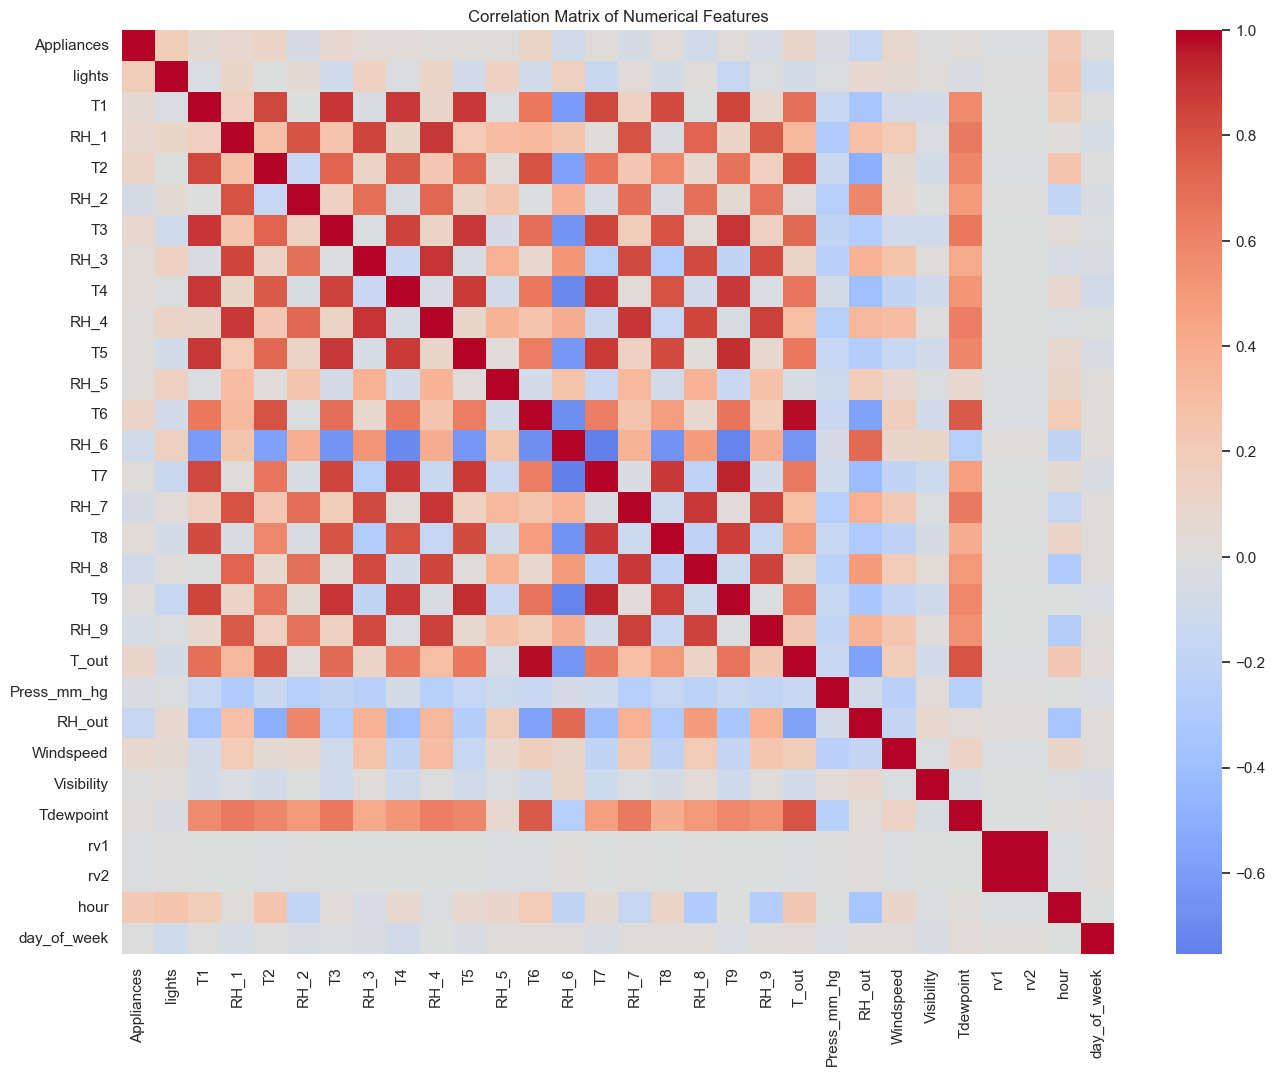

In [29]:
correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Matrix of Numerical Features")

plt.show()

In [30]:
feature_corr = df.select_dtypes(include=np.number).drop(
    columns=["Appliances"]
).corr()

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

strong_correlations = (
    upper_triangle.stack()
    .reset_index()
)

strong_correlations.columns = ["Feature_1", "Feature_2", "Correlation"]

strong_correlations["Absolute_Correlation"] = (
    strong_correlations["Correlation"].abs()
)

strong_correlations = strong_correlations.sort_values(
    "Absolute_Correlation",
    ascending=False
)

display(strong_correlations.head(20))

,Feature_1,Feature_2,Correlation,Absolute_Correlation
400,rv1,rv2,1.000000,1.000000
260,T6,T_out,0.974787,0.974787
289,T7,T9,0.944776,0.944776
223,T5,T9,0.911055,0.911055
141,T3,T9,0.901324,0.901324
154,RH_3,RH_4,0.898978,0.898978
201,RH_4,RH_7,0.894301,0.894301
31,T1,T3,0.892402,0.892402
184,T4,T9,0.889439,0.889439
133,T3,T5,0.888169,0.888169


In [31]:
# ============================================
# 8. Data Leakage Analysis
# ============================================

target = "Appliances"

# Check for columns identical to target
identical_to_target = []

for column in df.columns:
    if column != target:
        if df[column].equals(df[target]):
            identical_to_target.append(column)

print("Columns identical to target:")
print(identical_to_target)

Columns identical to target:
[]


In [32]:
target_correlations = (
    df.select_dtypes(include=np.number)
      .corr()["Appliances"]
      .drop("Appliances")
      .sort_values(key=abs, ascending=False)
)

display(target_correlations.head(10))

hour         0.216792
lights       0.197278
RH_out      -0.152282
T2           0.120073
T6           0.117638
T_out        0.099155
RH_8        -0.094039
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
Name: Appliances, dtype: float64

In [33]:
print("Date range:")
print(df["date"].min(), "to", df["date"].max())

print("\nNumber of rows:", len(df))

print("\nTime interval:")
print(df["date"].diff().value_counts().head())

Date range:
2016-01-11 17:00:00 to 2016-05-27 18:00:00

Number of rows: 19735

Time interval:
date
0 days 00:10:00    19734
Name: count, dtype: int64


In [34]:
print("Data Leakage Analysis Summary")
print("-" * 40)

if len(identical_to_target) == 0:
    print("✓ No feature identical to the target was found.")
else:
    print("⚠ Potential direct leakage detected:", identical_to_target)

print("\n✓ Target variable:", target)
print("✓ Temporal ordering should be preserved during model train/test splitting.")
print("✓ Future information must not be used to create predictors.")

Data Leakage Analysis Summary
----------------------------------------
✓ No feature identical to the target was found.

✓ Target variable: Appliances
✓ Temporal ordering should be preserved during model train/test splitting.
✓ Future information must not be used to create predictors.


In [35]:
# ============================================
# 9. Noise & Outlier Analysis
# ============================================

numeric_columns = df.select_dtypes(include=np.number).columns

outlier_counts = {}

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_counts[column] = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

outlier_counts = (
    pd.Series(outlier_counts)
    .sort_values(ascending=False)
)

display(outlier_counts)

lights         4483
Visibility     2522
Appliances     2138
RH_5           1330
T2              546
T1              515
T6              515
T_out           436
RH_out          239
RH_2            235
Press_mm_hg     219
T3              217
Windspeed       214
T4              186
T5              179
RH_1            146
T8               71
RH_7             42
RH_9             21
RH_8             17
RH_3             15
Tdewpoint        10
T7                2
T9                0
RH_6              0
RH_4              0
rv1               0
rv2               0
hour              0
day_of_week       0
dtype: int64

In [36]:
outlier_percentage = (
    outlier_counts / len(df) * 100
).sort_values(ascending=False)

outlier_summary = pd.DataFrame({
    "Outlier_Count": outlier_counts,
    "Outlier_Percentage": outlier_percentage
})

display(outlier_summary)

,Outlier_Count,Outlier_Percentage
lights,4483,22.715987
Visibility,2522,12.779326
Appliances,2138,10.833544
RH_5,1330,6.739296
T2,546,2.766658
T1,515,2.609577
T6,515,2.609577
T_out,436,2.209273
RH_out,239,1.211046
RH_2,235,1.190778


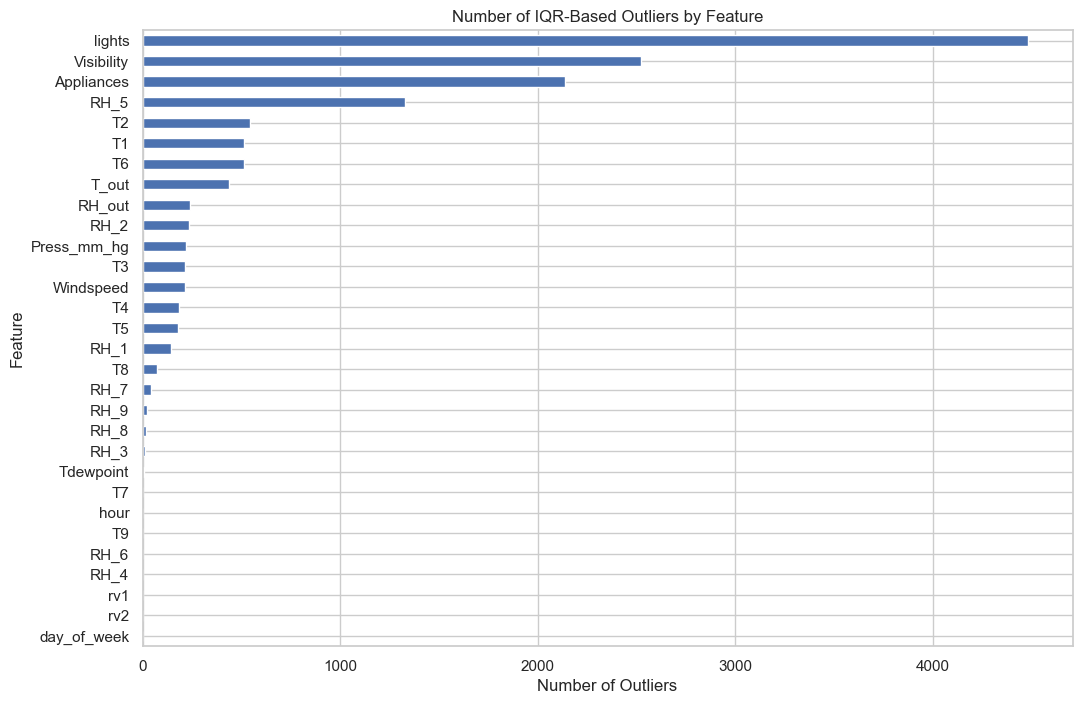

In [37]:
plt.figure(figsize=(12, 8))

outlier_counts.sort_values().plot(kind="barh")

plt.title("Number of IQR-Based Outliers by Feature")
plt.xlabel("Number of Outliers")
plt.ylabel("Feature")

plt.show()

In [38]:
target = "Appliances"

Q1 = df[target].quantile(0.25)
Q3 = df[target].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

target_outliers = df[
    (df[target] < lower_bound) |
    (df[target] > upper_bound)
]

print("Target:", target)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(target_outliers))
print("Outlier Percentage:", len(target_outliers) / len(df) * 100)

Target: Appliances
Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower Bound: -25.0
Upper Bound: 175.0
Outlier Count: 2138
Outlier Percentage: 10.833544464149988


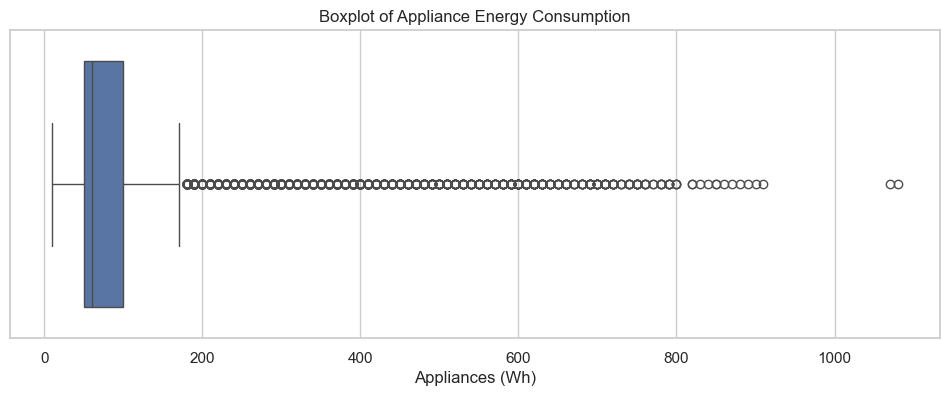

In [39]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=df["Appliances"])

plt.title("Boxplot of Appliance Energy Consumption")
plt.xlabel("Appliances (Wh)")

plt.show()

In [40]:
top_consumption = df.nlargest(
    10,
    "Appliances"
)[["date", "Appliances"]]

display(top_consumption)

,date,Appliances
731,2016-01-16 18:50:00,1080
1451,2016-01-21 18:50:00,1070
432,2016-01-14 17:00:00,910
12088,2016-04-04 15:40:00,900
1452,2016-01-21 19:00:00,890
10668,2016-03-25 19:00:00,880
14693,2016-04-22 17:50:00,870
9031,2016-03-14 10:10:00,860
1821,2016-01-24 08:30:00,850
19582,2016-05-26 16:40:00,850


In [41]:
# Top 20 highest appliance consumption records

top_consumption = df.nlargest(20, "Appliances")[
    ["date", "Appliances", "hour"]
]

display(top_consumption)

,date,Appliances,hour
731,2016-01-16 18:50:00,1080,18
1451,2016-01-21 18:50:00,1070,18
432,2016-01-14 17:00:00,910,17
12088,2016-04-04 15:40:00,900,15
1452,2016-01-21 19:00:00,890,19
10668,2016-03-25 19:00:00,880,19
14693,2016-04-22 17:50:00,870,17
9031,2016-03-14 10:10:00,860,10
1821,2016-01-24 08:30:00,850,8
19582,2016-05-26 16:40:00,850,16


In [42]:
daily_consumption = (
    df.set_index("date")["Appliances"]
    .resample("D")
    .mean()
)

display(daily_consumption.describe())

count    138.000000
mean      97.963041
std       30.470787
min       37.500000
25%       75.572917
50%       92.708333
75%      113.298611
max      188.541667
Name: Appliances, dtype: float64

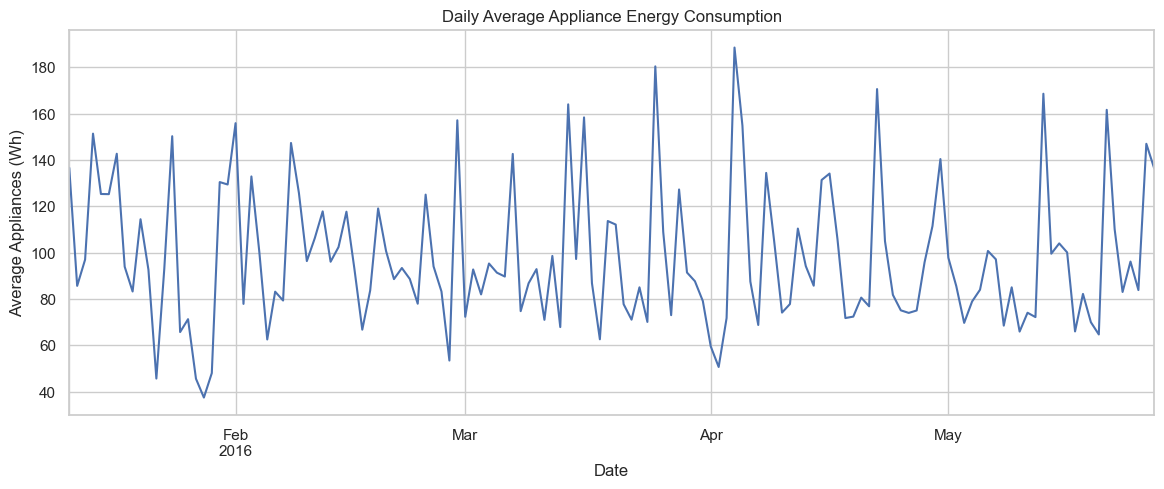

In [43]:
plt.figure(figsize=(14, 5))

daily_consumption.plot()

plt.title("Daily Average Appliance Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average Appliances (Wh)")
plt.show()

In [44]:
top_days = daily_consumption.sort_values(ascending=False).head(10)

display(top_days)

date
2016-04-04    188.541667
2016-03-25    180.416667
2016-04-22    170.625000
2016-05-13    168.611111
2016-03-14    164.027778
2016-05-21    161.666667
2016-03-16    158.402778
2016-02-29    157.152778
2016-02-01    155.902778
2016-04-05    154.861111
Name: Appliances, dtype: float64

In [45]:
hourly_consumption = df.groupby("hour")["Appliances"].mean()

peak_hour = hourly_consumption.idxmax()
peak_value = hourly_consumption.max()

print("Peak Hour:", peak_hour)
print("Average Consumption at Peak Hour:", peak_value)

Peak Hour: 18
Average Consumption at Peak Hour: 190.36452004860269


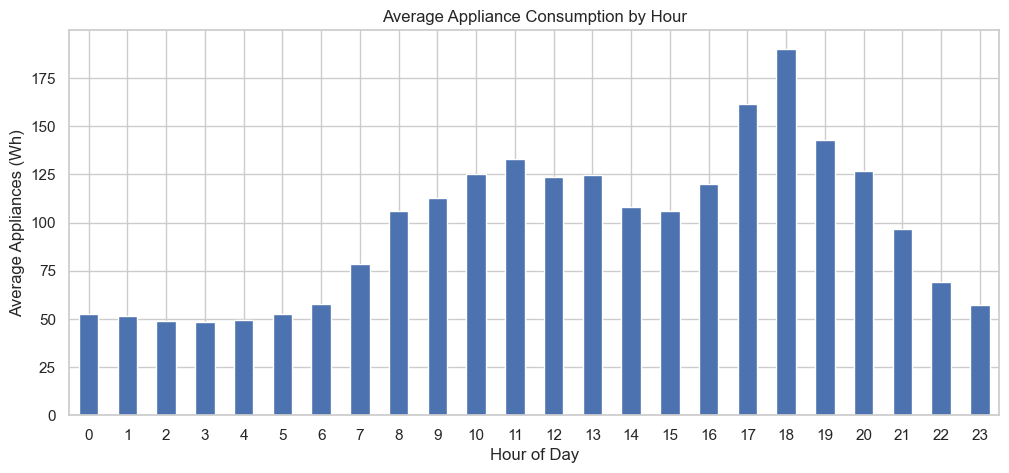

In [46]:
plt.figure(figsize=(12, 5))

hourly_consumption.plot(kind="bar")

plt.title("Average Appliance Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Appliances (Wh)")
plt.xticks(rotation=0)
plt.show()

In [47]:
high_consumption_hours = hourly_consumption[
    hourly_consumption > hourly_consumption.mean()
].sort_values(ascending=False)

display(high_consumption_hours)

hour
18    190.364520
17    161.352657
19    143.065693
11    133.126521
20    126.982968
10    125.377129
13    124.744526
12    123.637470
16    119.902676
9     112.785888
14    108.284672
8     106.143552
15    105.827251
Name: Appliances, dtype: float64

In [48]:
day_hour_consumption = pd.pivot_table(
    df,
    values="Appliances",
    index="day_name",
    columns="hour",
    aggfunc="mean"
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_hour_consumption = day_hour_consumption.reindex(day_order)

display(day_hour_consumption)

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
day_name,,,,,,,,,,,,,,,,,,,,,,,,
Monday,53.684211,52.719298,50.964912,50.175439,50.438596,54.824561,56.228070,71.403509,94.035088,96.052632,151.842105,178.421053,154.561404,177.982456,151.228070,166.052632,144.736842,190.166667,189.083333,144.833333,148.916667,100.000000,76.166667,63.333333
Tuesday,66.083333,56.250000,49.083333,47.083333,48.833333,59.833333,53.000000,82.333333,87.416667,74.083333,88.083333,75.583333,97.250000,101.750000,73.583333,76.083333,82.416667,164.166667,192.583333,155.333333,143.500000,90.583333,61.916667,64.166667
Wednesday,52.083333,52.583333,49.500000,48.416667,52.000000,55.083333,73.666667,72.166667,112.000000,116.250000,93.833333,75.833333,72.000000,80.833333,105.666667,89.416667,109.750000,133.166667,199.500000,149.416667,140.166667,102.416667,68.750000,53.833333
Thursday,49.250000,49.416667,48.416667,46.750000,47.333333,53.083333,50.333333,78.750000,91.333333,98.666667,109.833333,115.250000,111.083333,95.333333,77.166667,71.000000,121.083333,179.666667,218.916667,140.416667,115.500000,90.916667,58.833333,52.083333
Friday,49.000000,48.916667,49.333333,48.166667,48.916667,49.333333,72.833333,104.250000,128.000000,150.750000,140.500000,171.333333,170.250000,144.250000,127.750000,124.333333,128.500000,149.583333,173.478261,127.543860,102.192982,84.824561,65.263158,49.824561
Saturday,49.122807,48.245614,47.543860,47.719298,47.982456,46.403509,48.771930,68.157895,99.122807,120.964912,159.473684,181.929825,148.421053,168.157895,138.070175,134.824561,154.561404,162.192982,185.000000,152.017544,106.315789,95.614035,80.175439,59.122807
Sunday,50.000000,51.052632,48.684211,49.473684,50.000000,50.263158,48.157895,72.280702,131.403509,133.333333,137.719298,138.508772,114.210526,108.947368,87.105263,82.368421,100.263158,150.000000,172.105263,130.964912,130.175439,111.228070,73.508772,56.228070


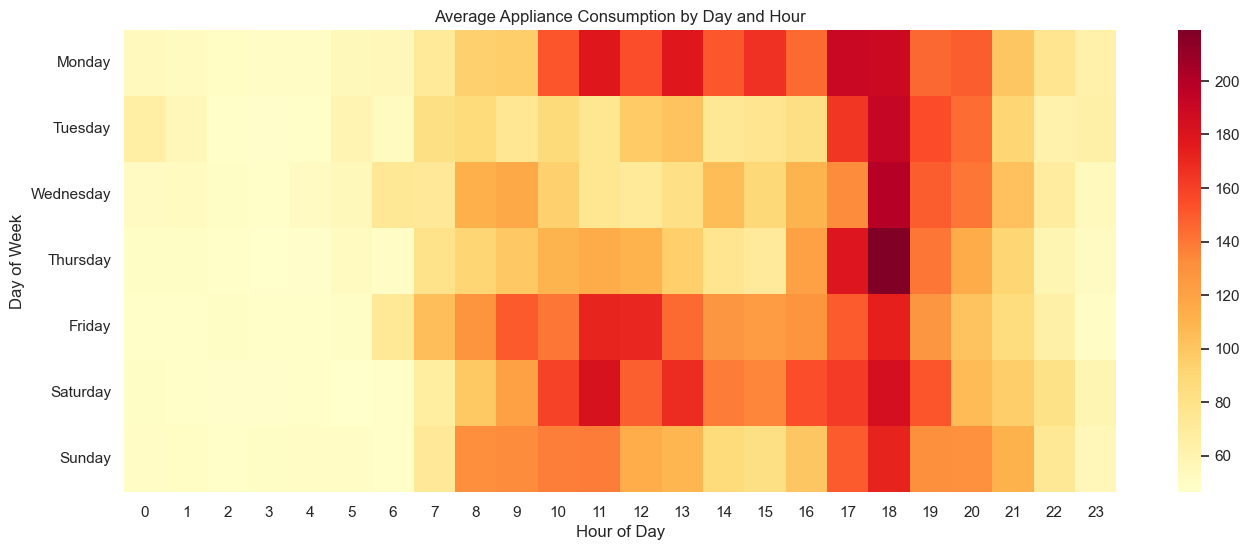

In [49]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    day_hour_consumption,
    annot=False,
    cmap="YlOrRd"
)

plt.title("Average Appliance Consumption by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.show()

In [50]:
model_df = df.copy()

print("Initial shape:", model_df.shape)
display(model_df.head())

Initial shape: (19735, 32)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week,day_name
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,17,0,Monday
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,17,0,Monday
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,17,0,Monday
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,17,0,Monday
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,17,0,Monday


In [51]:
print("Data types:")
display(model_df.dtypes)

Data types:


date           datetime64[ns]
Appliances              int64
lights                  int64
T1                    float64
RH_1                  float64
T2                    float64
RH_2                  float64
T3                    float64
RH_3                  float64
T4                    float64
RH_4                  float64
T5                    float64
RH_5                  float64
T6                    float64
RH_6                  float64
T7                    float64
RH_7                  float64
T8                    float64
RH_8                  float64
T9                    float64
RH_9                  float64
T_out                 float64
Press_mm_hg           float64
RH_out                float64
Windspeed             float64
Visibility            float64
Tdewpoint             float64
rv1                   float64
rv2                   float64
hour                    int32
day_of_week             int32
day_name               object
dtype: object

In [52]:
missing_values = model_df.isnull().sum()

display(
    missing_values[missing_values > 0]
)

Series([], dtype: int64)

In [53]:
duplicate_count = model_df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [54]:
model_df = model_df.sort_values("date").reset_index(drop=True)

print("Data sorted by date.")
display(model_df.head())

Data sorted by date.


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week,day_name
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,17,0,Monday
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,17,0,Monday
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,17,0,Monday
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,17,0,Monday
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,17,0,Monday


In [55]:
time_diff = model_df["date"].diff().dropna()

print("Minimum time interval:", time_diff.min())
print("Maximum time interval:", time_diff.max())
print("Number of non-10-minute intervals:", (time_diff != pd.Timedelta(minutes=10)).sum())

Minimum time interval: 0 days 00:10:00
Maximum time interval: 0 days 00:10:00
Number of non-10-minute intervals: 0


In [56]:
# Check basic physical/range constraints

range_checks = {
    "Appliances < 0": (model_df["Appliances"] < 0).sum(),
    "lights < 0": (model_df["lights"] < 0).sum(),
    "Humidity < 0": (model_df.filter(like="RH_") < 0).sum().sum(),
    "Humidity > 100": (model_df.filter(like="RH_") > 100).sum().sum(),
    "Windspeed < 0": (model_df["Windspeed"] < 0).sum(),
    "Visibility < 0": (model_df["Visibility"] < 0).sum(),
}

display(pd.Series(range_checks, name="Count"))

Appliances < 0    0
lights < 0        0
Humidity < 0      0
Humidity > 100    0
Windspeed < 0     0
Visibility < 0    0
Name: Count, dtype: int64

In [57]:
print("Number of columns:", len(model_df.columns))
print("\nColumns:")
print(model_df.columns.tolist())

Number of columns: 32

Columns:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'day_of_week', 'day_name']


In [58]:
print("Outlier treatment decision:")
print("- No rows removed based only on IQR.")
print("- High appliance consumption values are retained.")
print("- Architect should consider robust modeling/evaluation if necessary.")

Outlier treatment decision:
- No rows removed based only on IQR.
- High appliance consumption values are retained.
- Architect should consider robust modeling/evaluation if necessary.


In [59]:
final_model_df = model_df.drop(columns=["day_name"], errors="ignore").copy()

print("Final dataset shape:", final_model_df.shape)
display(final_model_df.head())

Final dataset shape: (19735, 31)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,17,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,17,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,17,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,17,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,17,0


In [60]:
print("===== FINAL VALIDATION =====")

print("Shape:", final_model_df.shape)
print("Missing values:", final_model_df.isnull().sum().sum())
print("Duplicate rows:", final_model_df.duplicated().sum())
print("Target exists:", "Appliances" in final_model_df.columns)
print("Date exists:", "date" in final_model_df.columns)
print("Date sorted:", final_model_df["date"].is_monotonic_increasing)

print("\nFinal columns:")
print(final_model_df.columns.tolist())

===== FINAL VALIDATION =====
Shape: (19735, 31)
Missing values: 0
Duplicate rows: 0
Target exists: True
Date exists: True
Date sorted: True

Final columns:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'day_of_week']


In [61]:
output_file = "appliances_energy_prepared.csv"

final_model_df.to_csv(output_file, index=False)

print(f"Dataset saved successfully: {output_file}")

Dataset saved successfully: appliances_energy_prepared.csv


In [62]:
check_df = pd.read_csv(output_file)

print("Saved dataset shape:", check_df.shape)
print("Missing values:", check_df.isnull().sum().sum())
print("Duplicate rows:", check_df.duplicated().sum())

display(check_df.head())

Saved dataset shape: (19735, 31)
Missing values: 0
Duplicate rows: 0


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour,day_of_week
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,17,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,17,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,17,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,17,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,17,0


In [63]:
print("========== ANALYST HANDOFF REPORT ==========")

print("\nDataset:")
print(f"- Rows: {final_model_df.shape[0]}")
print(f"- Columns: {final_model_df.shape[1]}")

print("\nTarget:")
print("- Appliances")

print("\nData Quality:")
print(f"- Missing values: {final_model_df.isnull().sum().sum()}")
print(f"- Duplicate rows: {final_model_df.duplicated().sum()}")
print(f"- Time sorted: {final_model_df['date'].is_monotonic_increasing}")

print("\nFeature Engineering:")
print("- hour: extracted from date")
print("- day_of_week: extracted from date")

print("\nOutliers:")
print("- No rows removed based only on IQR analysis.")

print("\nData Leakage:")
print("- No direct target leakage detected.")

print("\nFinal file:")
print(f"- {output_file}")

print("\n========== READY FOR ARCHITECT ==========")

========== ANALYST HANDOFF REPORT ==========

Dataset:
- Rows: 19735
- Columns: 31

Target:
- Appliances

Data Quality:
- Missing values: 0
- Duplicate rows: 0
- Time sorted: True

Feature Engineering:
- hour: extracted from date
- day_of_week: extracted from date

Outliers:
- No rows removed based only on IQR analysis.

Data Leakage:
- No direct target leakage detected.

Final file:
- appliances_energy_prepared.csv

========== READY FOR ARCHITECT ==========


In [64]:
display(
    pd.DataFrame({
        "Column": final_model_df.columns,
        "Data_Type": final_model_df.dtypes.astype(str).values,
        "Missing": final_model_df.isnull().sum().values,
        "Unique_Values": final_model_df.nunique().values
    })
)

,Column,Data_Type,Missing,Unique_Values
0,date,datetime64[ns],0,19735
1,Appliances,int64,0,92
2,lights,int64,0,8
3,T1,float64,0,722
4,RH_1,float64,0,2547
5,T2,float64,0,1650
6,RH_2,float64,0,3376
7,T3,float64,0,1426
8,RH_3,float64,0,2618
9,T4,float64,0,1390
